In [1]:
!pip install -q ultralytics open3d
!pip install -q --no-deps --ignore-requires-python git+https://github.com/ByteDance-Seed/Depth-Anything-3 evo "moviepy==1.0.3" proglog
!pip install -q addict einops omegaconf trimesh plyfile pycolmap

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
depth-anything-3 0.0.0 requires e3nn, which is not installed.
depth-anything-3 0.0.0 requires pillow-heif, which is not installed.
depth-anything-3 0.0.0 requires pre-commit, which is not installed.
depth-anything-3 0.0.0 requires xformers, which is not installed.
depth-anything-3 0.0.0 requires numpy<2, but you have numpy 2.1.3 which is incompatible.


In [2]:
import os, glob, time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import open3d as o3d
from PIL import Image, ImageOps
from ultralytics import YOLO
from transformers import AutoImageProcessor, AutoModelForDepthEstimation

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device", device)

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Device cuda


In [3]:
DEPTH_MODEL = "v3"
VEHICLES = [1, 2, 3, 5, 7]    # COCO ids for bicycle, car, motorcycle, bus, truck

yolo = YOLO("yolov8m.pt")
from depth_anything_3.api import DepthAnything3
depth_model = DepthAnything3.from_pretrained("depth-anything/DA3METRIC-LARGE").to(device).eval()

/usr/local/lib/python3.13/dist-packages/depth_anything_3/cfg.py:25: UserWarning: register_new_resolver() is deprecated and will be removed in a future release.
Use register_resolver() instead.
See https://github.com/hydra-ecosystem/omegaconf/issues/426 for migration instructions.

  OmegaConf.register_new_resolver("eval", eval)
/usr/local/lib/python3.13/dist-packages/moviepy/config_defaults.py:47: SyntaxWarning: invalid escape sequence '\P'
  IMAGEMAGICK_BINARY = r"C:\Program Files\ImageMagick-6.8.8-Q16\magick.exe"
/usr/local/lib/python3.13/dist-packages/moviepy/video/io/ffmpeg_reader.py:294: SyntaxWarning: invalid escape sequence '\d'
  lines_video = [l for l in lines if ' Video: ' in l and re.search('\d+x\d+', l)]
/usr/local/lib/python3.13/dist-packages/moviepy/video/io/ffmpeg_reader.py:367: SyntaxWarning: invalid escape sequence '\d'
  rotation_lines = [l for l in lines if 'rotate          :' in l and re.search('\d+$', l)]
/usr/local/lib/python3.13/dist-packages/moviepy/video/io/ffm

[WARN ] Dependency `gsplat` is required for rendering 3DGS. Install via: pip install git+https://github.com/nerfstudio-project/gsplat.git@0b4dddf04cb687367602c01196913cde6a743d70


config.json:   0%|          | 0.00/847 [00:00<?, ?B/s]

[INFO ] using MLP layer as FFN


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.34GB            

model.safetensors: downloading bytes:           |  0.00B            

In [4]:
def detect(img):
    r = yolo(Image.fromarray(img), classes=VEHICLES, conf=0.4, verbose=False)[0]
    boxes = r.boxes.xyxy.cpu().numpy().astype(int)
    names = [r.names[int(c)] for c in r.boxes.cls]
    return [(*b, n) for b, n in zip(boxes, names)]

In [5]:
@torch.no_grad()
def estimate_depth(img, K):
    pred = depth_model.inference([img], process_res=504, process_res_method="lower_bound_resize")
    d = pred.depth[0]                                   # canonical depth
    h, w = d.shape
    focal = (K[0, 0] * w / img.shape[1] + K[1, 1] * h / img.shape[0]) / 2
    d = d * focal / 300
    if pred.sky is not None:
        d[pred.sky[0]] = np.nan 
    d = torch.from_numpy(d)[None, None]
    d = torch.nn.functional.interpolate(d.float(), size=img.shape[:2], mode="bilinear", align_corners=False)
    return d[0, 0].cpu().numpy()

In [6]:
def backproject(depth, K):
    h, w = depth.shape
    u, v = np.meshgrid(np.arange(w), np.arange(h))
    x = (u - K[0, 2]) * depth / K[0, 0]
    y = (v - K[1, 2]) * depth / K[1, 1]
    return np.dstack([x, y, depth])

In [7]:
def inner(box, shrink=0.25):
    x1, y1, x2, y2 = box[:4]
    dx, dy = (x2 - x1) * shrink, (y2 - y1) * shrink
    x1, y1 = int(x1 + dx), int(y1 + dy)
    return x1, y1, max(int(x2 - dx), x1 + 1), max(int(y2 - dy), y1 + 1)

In [8]:
def box_points(xyz, box):
    x1, y1, x2, y2 = inner(box)
    return xyz[y1:y2, x1:x2].reshape(-1, 3)

In [9]:
def box_points(xyz, box):
    x1, y1, x2, y2 = inner(box)
    return xyz[y1:y2, x1:x2].reshape(-1, 3)

In [10]:
def vehicle_distances(xyz, boxes):
    return [float(np.nanmedian(np.linalg.norm(box_points(xyz, b), axis=1))) for b in boxes]

In [11]:
def run(img, K):
    t0 = time.perf_counter()
    boxes = detect(img)
    t1 = time.perf_counter()
    depth = estimate_depth(img, K)
    t2 = time.perf_counter()
    xyz = backproject(depth, K)
    dists = vehicle_distances(xyz, boxes)
    print(f"{len(boxes)} vehicles, YOLO {1000 * (t1 - t0):.0f} ms, depth {1000 * (t2 - t1):.0f} ms")
    return boxes, depth, xyz, dists

In [12]:
def draw(img, boxes, dists=None):
    plt.figure(figsize=(16, 6))
    plt.imshow(img)
    for i, (x1, y1, x2, y2, name) in enumerate(boxes):
        plt.gca().add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="lime", lw=2))
        label = f"{i} {name}" + (f"  {dists[i]:.1f} m" if dists is not None else "")
        plt.text(x1, y1 - 4, label, fontsize=11, bbox=dict(facecolor="lime", edgecolor="none", pad=1))
    plt.axis("off")
    plt.show()

In [13]:
def show_depth(img, depth):
    wide = img.shape[1] > 2 * img.shape[0]
    fig, ax = plt.subplots(2 if wide else 1, 1 if wide else 2, figsize=(16, 10 if wide else 6))
    ax[0].imshow(img)
    im = ax[1].imshow(depth, cmap="turbo", vmin=0, vmax=np.nanpercentile(depth, 95))
    ax[1].set_title("Predicted depth (m)")
    fig.colorbar(im, ax=ax[1], fraction=0.02)
    for a in ax:
        a.axis("off")
    plt.show()

In [14]:
def make_cloud(xyz, img, max_depth=60):
    keep = (xyz[..., 2] > 0) & (xyz[..., 2] < max_depth)
    pcd = o3d.geometry.PointCloud()
    pcd.points = o3d.utility.Vector3dVector(xyz[keep].astype(np.float64))
    pcd.colors = o3d.utility.Vector3dVector(img[keep] / 255.0)
    # pcd = pcd.voxel_down_sample(0.1)
    pcd = pcd.voxel_down_sample(0.001)
    pcd, _ = pcd.remove_statistical_outlier(nb_neighbors=20, std_ratio=2.0)
    return pcd

In [15]:
def labels_3d(xyz, boxes, dists):
    return [(np.nanmedian(box_points(xyz, b), axis=0), f"{i}  {d:.1f} m") for i, (b, d) in enumerate(zip(boxes, dists))]

In [16]:
def show_cloud(pcd, labels=(), extra=None, title=""):
    # plot axes are x right, y forward, z up
    p, c = np.asarray(pcd.points), np.asarray(pcd.colors)
    idx = np.random.default_rng(0).choice(len(p), min(len(p), 60000), replace=False)
    p, c = p[idx], c[idx]
    rgb = [f"rgb({r},{g},{b})" for r, g, b in (c * 255).astype(int)]
    data = [go.Scatter3d(x=p[:, 0], y=p[:, 2], z=-p[:, 1], mode="markers",
                         marker=dict(size=1.5, color=rgb), name="camera")]
    if extra is not None:
        data.append(go.Scatter3d(x=extra[:, 0], y=extra[:, 2], z=-extra[:, 1], mode="markers",
                                 marker=dict(size=1.5, color="red"), name="LiDAR"))
    for (x, y, z), text in labels:
        data.append(go.Scatter3d(x=[x], y=[z], z=[-y + 1.5], mode="text", text=[text],
                                 textfont=dict(size=14, color="yellow"), showlegend=False))
    fig = go.Figure(data)
    fig.update_layout(title=title, height=650, paper_bgcolor="black", font_color="white",
                      scene=dict(aspectmode="data", xaxis_visible=False, yaxis_visible=False, zaxis_visible=False,
                                 camera=dict(eye=dict(x=0, y=-1.2, z=0.6), up=dict(x=0, y=0, z=1))))
    fig.show()

In [17]:
def find_dir(name):
    hits = [p for p in glob.glob(f"/kaggle/input/**/{name}", recursive=True) if os.path.isdir(p)]
    hits.sort(key=lambda p: "training" not in p)
    assert hits, f"No {name} folder found. Add a KITTI object detection dataset as input."
    return hits[0]

IMG_DIR, VELO_DIR, CALIB_DIR = find_dir("image_2"), find_dir("velodyne"), find_dir("calib")
print(IMG_DIR, VELO_DIR, CALIB_DIR, sep="\n")

/kaggle/input/datasets/garymk/kitti-3d-object-detection-dataset/training/image_2
/kaggle/input/datasets/garymk/kitti-3d-object-detection-dataset/training/velodyne
/kaggle/input/datasets/garymk/kitti-3d-object-detection-dataset/training/calib


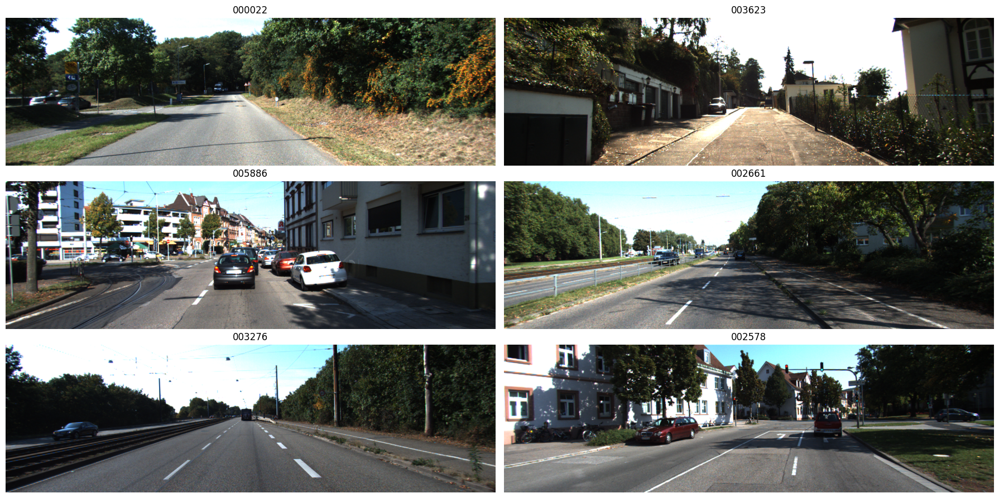

In [18]:

ids = sorted(f[:-4] for f in os.listdir(IMG_DIR) if f.endswith(".png"))
fig, ax = plt.subplots(3, 2, figsize=(18, 9))
for a, i in zip(ax.flat, np.random.default_rng().choice(ids, min(6, len(ids)), replace=False)):
    a.imshow(Image.open(f"{IMG_DIR}/{i}.png"))
    a.set_title(i)
    a.axis("off")
plt.tight_layout()
plt.show()

In [19]:
def load_calib(path):
    vals = {}
    for line in open(path):
        if ":" in line:
            key, nums = line.split(":", 1)
            vals[key] = np.array(nums.split(), dtype=float)
    return vals["P2"].reshape(3, 4), vals["R0_rect"].reshape(3, 3), vals["Tr_velo_to_cam"].reshape(3, 4)

In [20]:
def lidar_in_camera(velo, P2, R0, Tr):
    pts = velo[:, :3] @ Tr[:, :3].T + Tr[:, 3]    
    pts = pts @ R0.T
    K = P2[:, :3].copy()
    pts = pts + np.linalg.solve(K, P2[:, 3])        
    return pts[pts[:, 2] > 1.0], K

In [21]:
FRAME_ID = "000008"
img = np.array(Image.open(f"{IMG_DIR}/{FRAME_ID}.png").convert("RGB"))
velo = np.fromfile(f"{VELO_DIR}/{FRAME_ID}.bin", dtype=np.float32).reshape(-1, 4)
lidar, K = lidar_in_camera(velo, *load_calib(f"{CALIB_DIR}/{FRAME_ID}.txt"))
print(img.shape, "focal length", round(K[0, 0], 1), "px")

(375, 1242, 3) focal length 721.5 px


[INFO ] Processed Images Done taking 0.08178234100341797 seconds. Shape:  torch.Size([1, 3, 504, 1666])
[INFO ] Model Forward Pass Done. Time: 3.04406476020813 seconds
[INFO ] Conversion to Prediction Done. Time: 0.0071833133697509766 seconds
8 vehicles, YOLO 4689 ms, depth 3166 ms


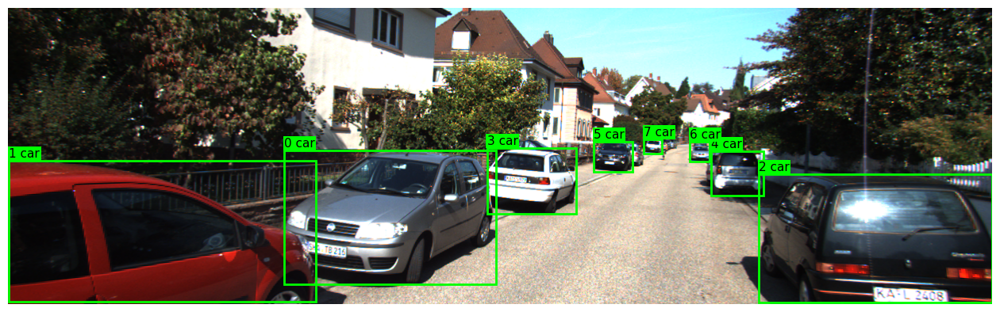

In [22]:
boxes, depth, xyz, dists = run(img, K)
draw(img, boxes)

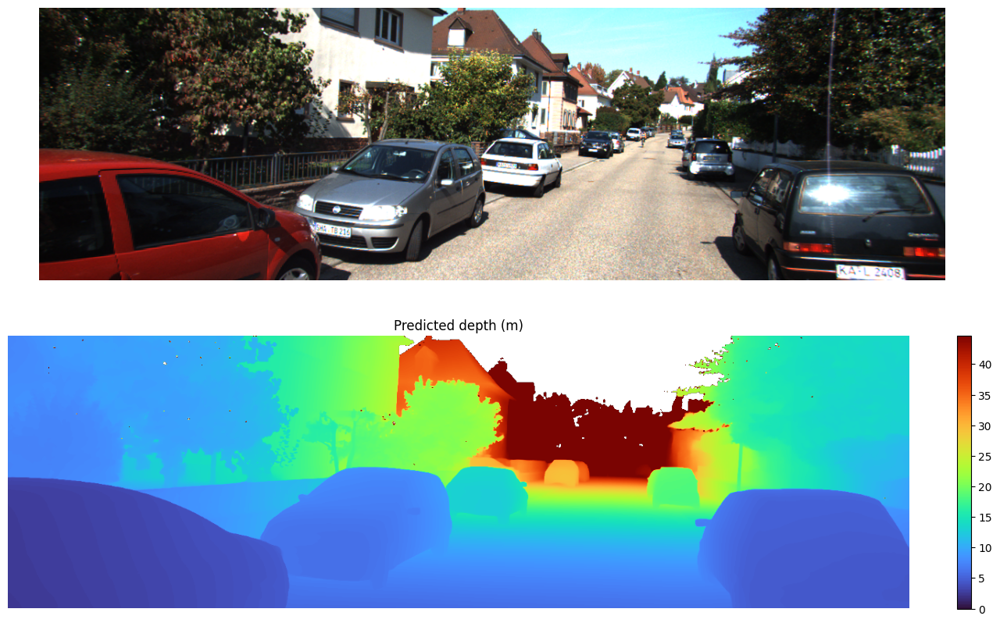

In [23]:
show_depth(img, depth)

In [24]:
pcd = make_cloud(xyz, img)
show_cloud(pcd, labels_3d(xyz, boxes, dists), title="Point cloud from one camera image")

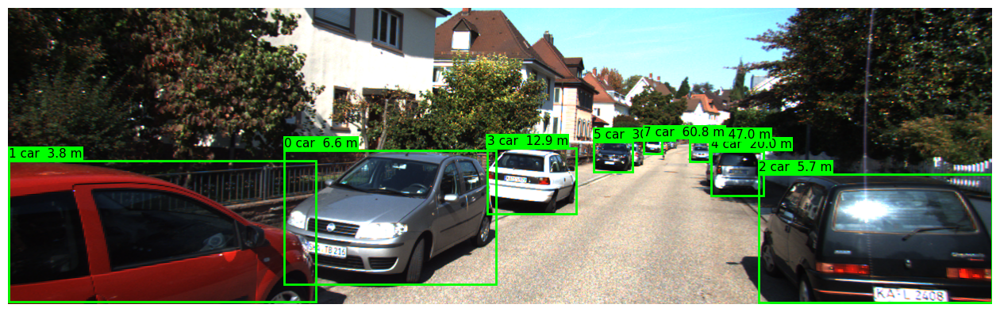

In [25]:
draw(img, boxes, dists)

kitti

In [26]:
def project(pts, K, shape):
    uv = pts @ K.T
    u, v = uv[:, 0] / uv[:, 2], uv[:, 1] / uv[:, 2]
    ok = (u >= 0) & (u < shape[1]) & (v >= 0) & (v < shape[0])
    return pts[ok], u[ok].astype(int), v[ok].astype(int)

In [27]:
def lidar_distance(box, pts, u, v):
    x1, y1, x2, y2 = inner(box)
    inside = (u >= x1) & (u < x2) & (v >= y1) & (v < y2)
    return float(np.median(np.linalg.norm(pts[inside], axis=1))) if inside.sum() >= 5 else np.nan

In [28]:
def sparse_scale(depth, pts, u, v, n=60, seed=0):
    pick = np.random.default_rng(seed).choice(len(pts), min(n, len(pts)), replace=False)
    return float(np.nanmedian(pts[pick, 2] / depth[v[pick], u[pick]])), pick

In [29]:
def lidar_check(img, K, lidar, n_sparse=60):
    boxes, depth, xyz, dists = run(img, K)
    pts, u, v = project(lidar, K, img.shape)
    s, pick = sparse_scale(depth, pts, u, v, n_sparse)
    # draw(img, boxes, dists)
    
    fused = [s * d for d in dists]
    print(f"Scale factor s = {s:.3f}")
    draw(img, boxes, dists) 
    draw(img, boxes, fused)

    plt.figure(figsize=(16, 6))
    plt.imshow(img)
    # plt.scatter(u, v, c=pts[:, 2], s=1, cmap="turbo", vmin=0, vmax=60)
    plt.scatter(u[pick], v[pick], s=50, facecolors="none", edgecolors="white", linewidths=1.5)
    plt.title(f"white circles {len(pick)} points used to fix the scale")
    plt.axis("off")
    plt.show()
    return xyz, s, pts


[INFO ] Processed Images Done taking 0.024620532989501953 seconds. Shape:  torch.Size([1, 3, 504, 1666])
[INFO ] Model Forward Pass Done. Time: 2.80942440032959 seconds
[INFO ] Conversion to Prediction Done. Time: 0.002038240432739258 seconds
8 vehicles, YOLO 40 ms, depth 2858 ms
Scale factor s = 1.020


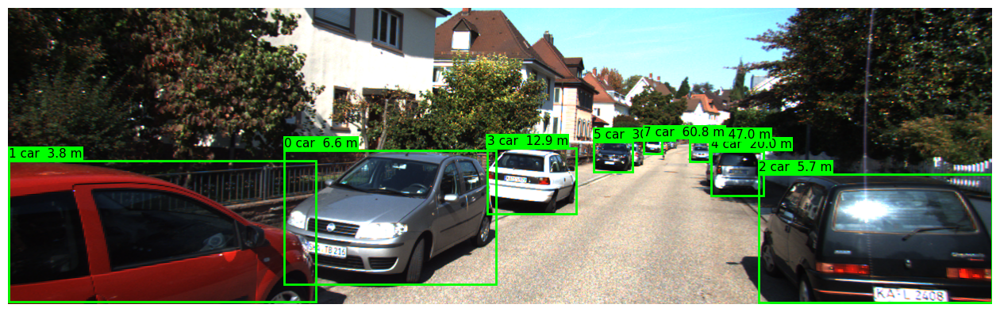

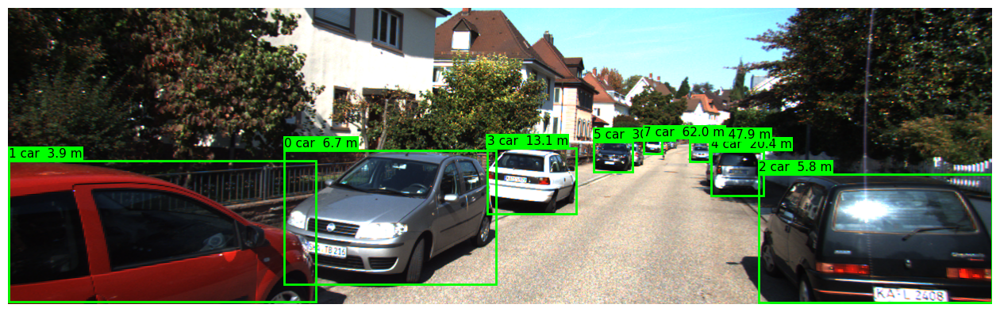

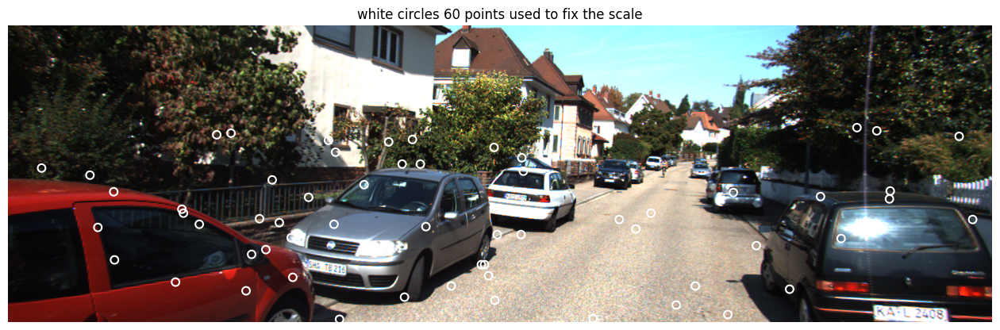

In [30]:
xyz, s, pts = lidar_check(img, K, lidar)

In [31]:
show_cloud(make_cloud(xyz, img), extra=pts, title="Camera points, LiDAR in red")
show_cloud(make_cloud(s * xyz, img), extra=pts, title="After the sparse scale fix")

[INFO ] Processed Images Done taking 0.017122507095336914 seconds. Shape:  torch.Size([1, 3, 504, 728])
[INFO ] Model Forward Pass Done. Time: 0.9395675659179688 seconds
[INFO ] Conversion to Prediction Done. Time: 0.0017306804656982422 seconds
3 vehicles, YOLO 66 ms, depth 970 ms


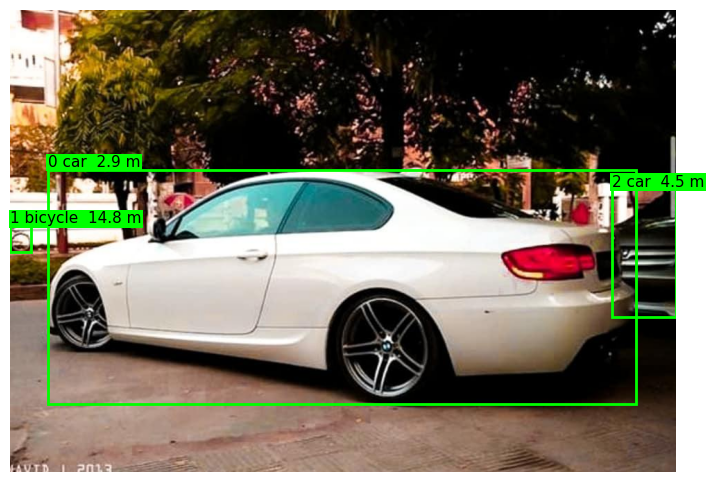

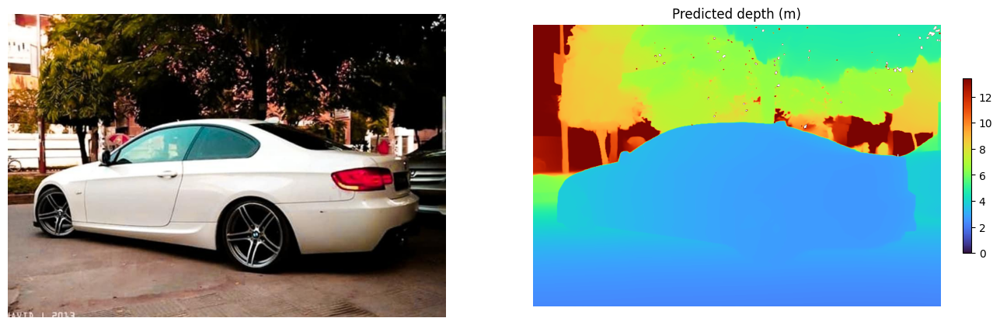

In [32]:
MY_IMAGE = "/kaggle/input/datasets/syednahinhossain/bangladeshi-license-plate-recognition-dataset/License Plate Localization/test/133872735_2282158335254696_5531650993354377220_n_jpg.rf.e5b089586bff725982c7e0e881627a87.jpg"
HFOV_DEG = 70          # horizontal field of view of a phone main camera

im = ImageOps.exif_transpose(Image.open(MY_IMAGE)).convert("RGB")
im.thumbnail((1280, 1280))
my_img = np.array(im)
h, w = my_img.shape[:2]
f = w / (2 * np.tan(np.radians(HFOV_DEG) / 2))
K_my = np.array([[f, 0, w / 2], [0, f, h / 2], [0, 0, 1]])

my_boxes, my_depth, my_xyz, my_dists = run(my_img, K_my)
draw(my_img, my_boxes, my_dists)
show_depth(my_img, my_depth)
show_cloud(make_cloud(my_xyz, my_img), labels_3d(my_xyz, my_boxes, my_dists), title="Point cloud from phone photo")
